<a href="https://colab.research.google.com/github/K3nleyy/fine-food-sentiment-analyzer/blob/main/notebooks/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

os.listdir('/content/drive/MyDrive/fine-food-sentiment-analyzer ')

['Reviews.csv']

In [3]:
import os

os.listdir("/content/drive/MyDrive")

['Sonam_s_Resume (1).pdf',
 'Sonam_Bhutia_Stimuler_Assignment.mov',
 'video1192949702.mp4',
 'Sonam_240410700089.mp4',
 'Sonam_s_Resume.pdf',
 'video1596966780.mp4',
 "Sonam's Final_OJL_Logbook_ (2).pdf.pdf",
 'Bike Usage Segmentation System.pdf',
 'Reviewed OJT Project Product Requirement Document (PRD) Template.gdoc',
 'fine-food-sentiment-analyzer ',
 '01_data_exploration.ipynb']

# **EDA**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "/content/drive/MyDrive/fine-food-sentiment-analyzer /Reviews.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [5]:
print("Rows and columns:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Rows and columns: (568454, 10)

Columns:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']

Data types:
Id                         int64
ProductId                 object
UserId                    object
ProfileName               object
HelpfulnessNumerator       int64
HelpfulnessDenominator     int64
Score                      int64
Time                       int64
Summary                   object
Text                      object
dtype: object


In [6]:
missing = df.isnull().sum()

print(missing)

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64


In [7]:
print("Total missing values:", missing.sum())

Total missing values: 53


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
print("Duplicate review texts:", df["Text"].duplicated().sum())

Duplicate review texts: 174875


### Initial EDA Observations

- The dataset contains 568,454 reviews and 10 columns.
- The dataset contains both structured features such as Score, Time and helpfulness counts, and unstructured text fields such as Summary and Text.
- Only 53 missing values were found, limited to ProfileName and Summary.
- There are no completely duplicated rows.
- 174,875 review texts are repeated, which needs to be considered when preparing the data and designing the train-test split.
- The Time column is stored as a Unix timestamp and will be converted to datetime for time-based analysis.

In [10]:
score_counts = df["Score"].value_counts().sort_index()

print(score_counts)

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


In [11]:
score_percent = df["Score"].value_counts(normalize=True).sort_index() * 100

print(score_percent.round(2))

Score
1     9.19
2     5.24
3     7.50
4    14.19
5    63.88
Name: proportion, dtype: float64


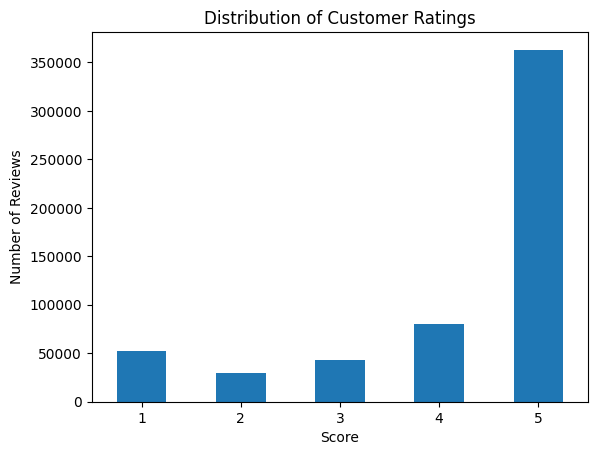

In [12]:
score_counts.plot(kind="bar")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Score")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

### Score Distribution Observations

- The dataset contains reviews with scores from 1 to 5.
- Score 5 is the dominant rating, accounting for 63.88% of all reviews.
- Scores 1 and 2 together account for 14.43% of the dataset.
- Score 3 accounts for 7.50% of the dataset.
- Scores 4 and 5 together account for 78.07% of the dataset.
- The distribution is therefore highly skewed toward positive ratings.
- Using the planned mapping of 1–2 = Negative, 3 = Neutral and 4–5 = Positive will create class imbalance.
- Because of this imbalance, model evaluation should not rely on accuracy alone; precision, recall, F1-score and the confusion matrix will also be considered.

In [13]:
df["text_char_count"] = df["Text"].str.len()

df["text_word_count"] = df["Text"].str.split().str.len()

df[["text_char_count", "text_word_count"]].describe()

,text_char_count,text_word_count
count,568454.000000,568454.000000
mean,436.222083,80.264023
std,445.339741,79.455384
min,12.000000,3.000000
25%,179.000000,33.000000
50%,302.000000,56.000000
75%,527.000000,98.000000
max,21409.000000,3432.000000


In [14]:
print("Average characters:", df["text_char_count"].mean())
print("Average words:", df["text_word_count"].mean())

print("Shortest review:", df["text_word_count"].min(), "words")
print("Longest review:", df["text_word_count"].max(), "words")

Average characters: 436.22208305333413
Average words: 80.26402312236347
Shortest review: 3 words
Longest review: 3432 words


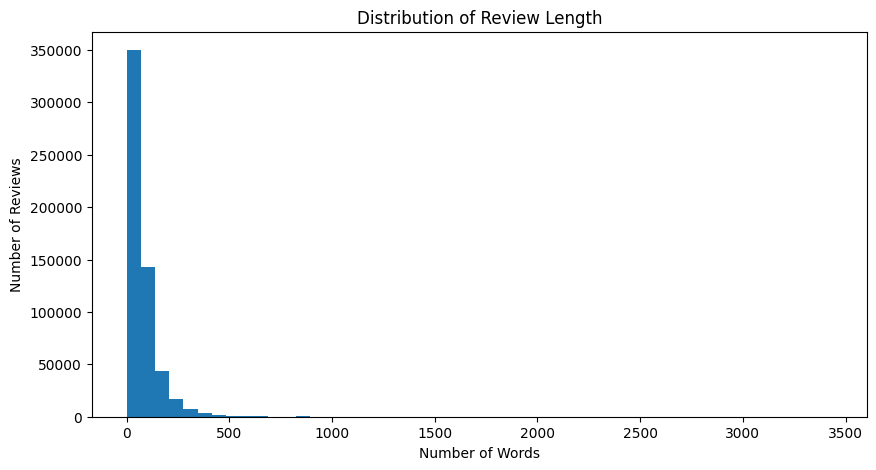

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(df["text_word_count"], bins=50)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

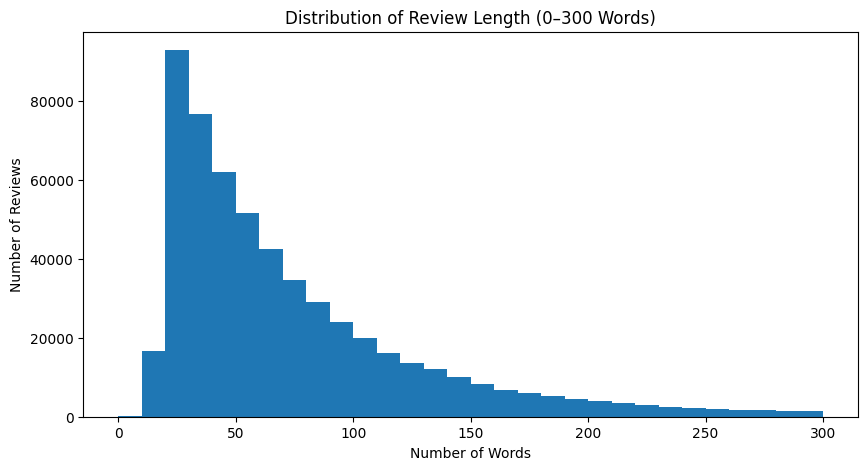

In [16]:
plt.figure(figsize=(10, 5))

plt.hist(df["text_word_count"], bins=30, range=(0, 300))

plt.title("Distribution of Review Length (0–300 Words)")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

<Figure size 1000x600 with 0 Axes>

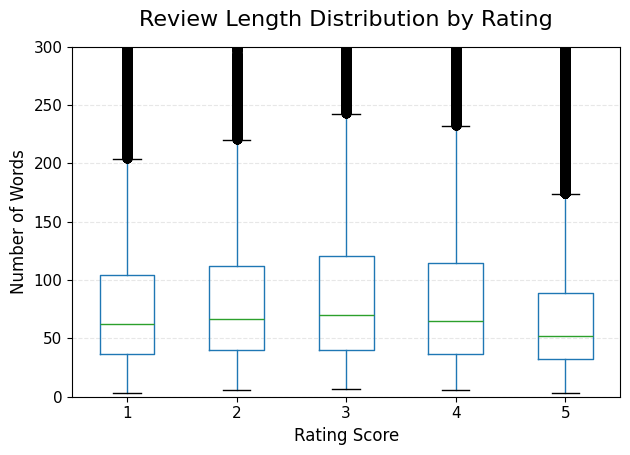

In [17]:
plt.figure(figsize=(10, 6))

df.boxplot(
    column="text_word_count",
    by="Score",
    grid=False
)

plt.suptitle("")
plt.title("Review Length Distribution by Rating", fontsize=16, pad=15)
plt.xlabel("Rating Score", fontsize=12)
plt.ylabel("Number of Words", fontsize=12)

plt.ylim(0, 300)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

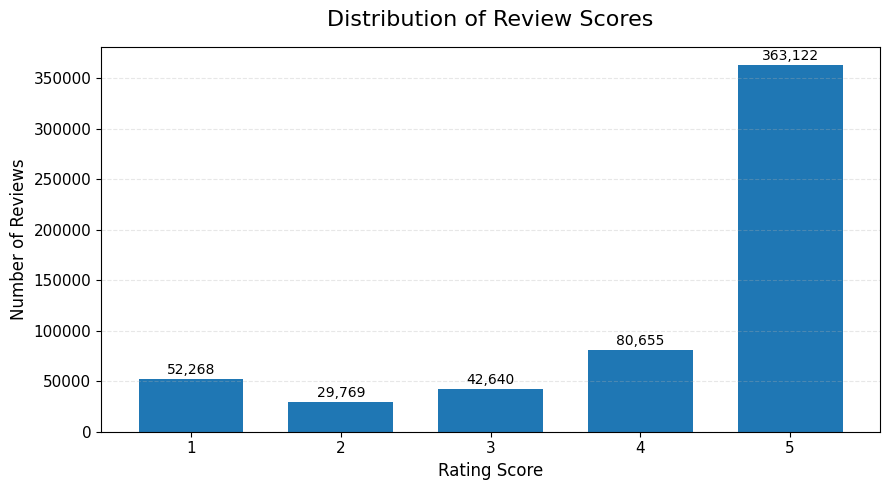

In [18]:
plt.figure(figsize=(9, 5))

ax = score_counts.plot(kind="bar", width=0.7)

plt.title("Distribution of Review Scores", fontsize=16, pad=15)
plt.xlabel("Rating Score", fontsize=12)
plt.ylabel("Number of Reviews", fontsize=12)

plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)

plt.grid(axis="y", linestyle="--", alpha=0.3)

# Add values above bars
for i, value in enumerate(score_counts):
    ax.text(
        i,
        value + 5000,
        f"{value:,}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [19]:
df["helpfulness_ratio"] = (
    df["HelpfulnessNumerator"] /
    df["HelpfulnessDenominator"].replace(0, np.nan)
)

In [20]:
print(df["helpfulness_ratio"].describe())

count    298402.000000
mean          0.776975
std           0.346321
min           0.000000
25%           0.600000
50%           1.000000
75%           1.000000
max           3.000000
Name: helpfulness_ratio, dtype: float64


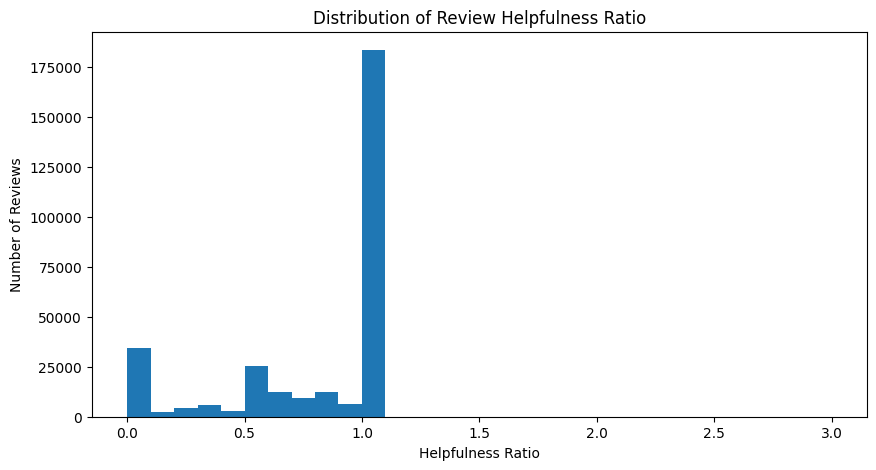

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(df["helpfulness_ratio"].dropna(), bins=30)

plt.title("Distribution of Review Helpfulness Ratio")
plt.xlabel("Helpfulness Ratio")
plt.ylabel("Number of Reviews")

plt.show()

In [22]:
df["review_date"] = pd.to_datetime(df["Time"], unit="s")

In [23]:
print(df["review_date"].min())
print(df["review_date"].max())

1999-10-08 00:00:00
2012-10-26 00:00:00


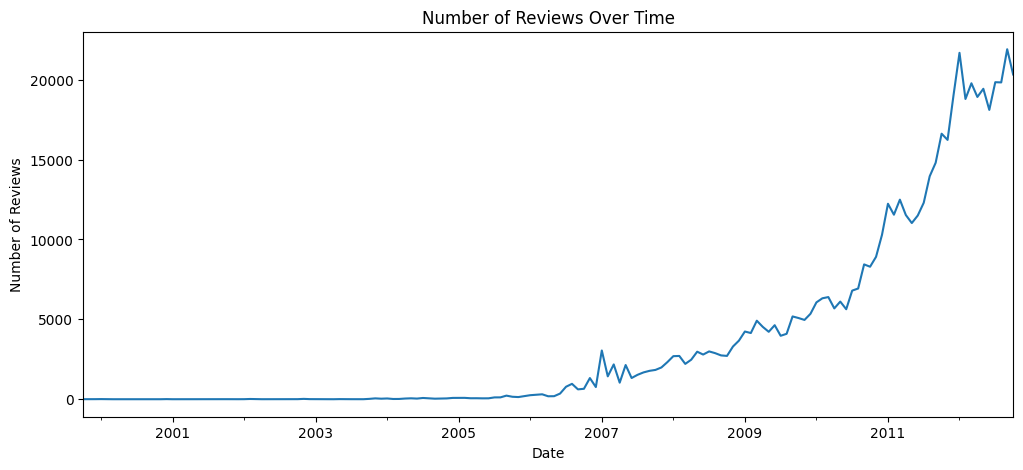

In [24]:
monthly_reviews = (
    df.set_index("review_date")
      .resample("ME")
      .size()
)

plt.figure(figsize=(12, 5))

monthly_reviews.plot()

plt.title("Number of Reviews Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Reviews")

plt.show()

In [25]:
corr_cols = [
    "HelpfulnessNumerator",
    "HelpfulnessDenominator",
    "Score",
    "text_char_count",
    "text_word_count",
    "helpfulness_ratio"
]

corr_matrix = df[corr_cols].corr()

print(corr_matrix)

                        HelpfulnessNumerator  HelpfulnessDenominator  \
HelpfulnessNumerator                1.000000                0.974689   
HelpfulnessDenominator              0.974689                1.000000   
Score                              -0.032590               -0.097986   
text_char_count                     0.170834                0.175505   
text_word_count                     0.169328                0.173198   
helpfulness_ratio                   0.112788                0.006012   

                           Score  text_char_count  text_word_count  \
HelpfulnessNumerator   -0.032590         0.170834         0.169328   
HelpfulnessDenominator -0.097986         0.175505         0.173198   
Score                   1.000000        -0.077334        -0.077017   
text_char_count        -0.077334         1.000000         0.995469   
text_word_count        -0.077017         0.995469         1.000000   
helpfulness_ratio       0.377151         0.039126         0.040870   

    

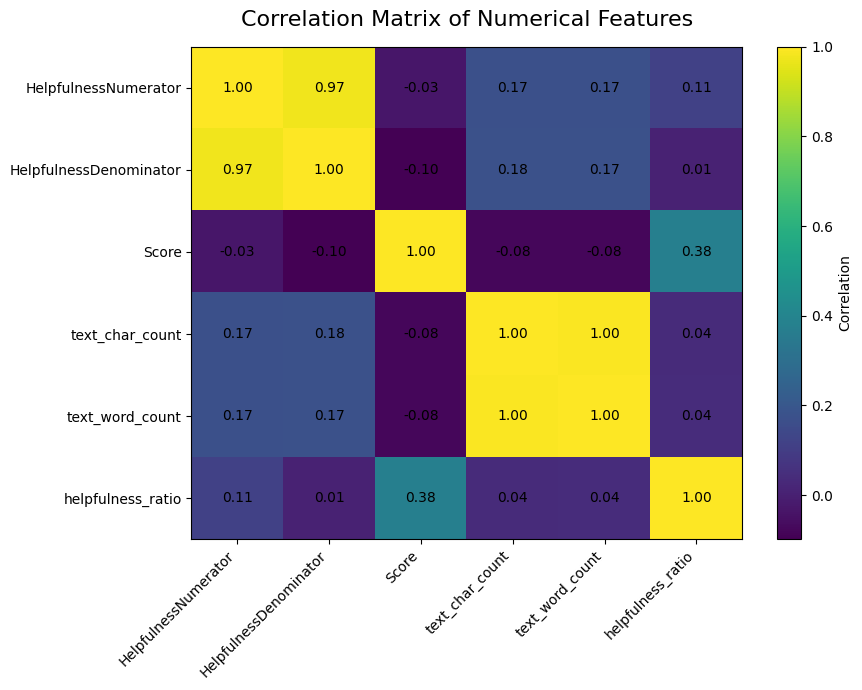

In [26]:
corr_cols = [
    "HelpfulnessNumerator",
    "HelpfulnessDenominator",
    "Score",
    "text_char_count",
    "text_word_count",
    "helpfulness_ratio"
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))

plt.imshow(corr_matrix, aspect="auto")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

# Show correlation values inside the cells
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        plt.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

plt.colorbar(label="Correlation")

plt.title("Correlation Matrix of Numerical Features", fontsize=16, pad=15)

plt.tight_layout()
plt.show()

In [27]:
avg_words_by_score = df.groupby("Score")["text_word_count"].mean()

print(avg_words_by_score)

Score
1    87.323697
2    90.040881
3    95.645755
4    91.393156
5    74.168167
Name: text_word_count, dtype: float64


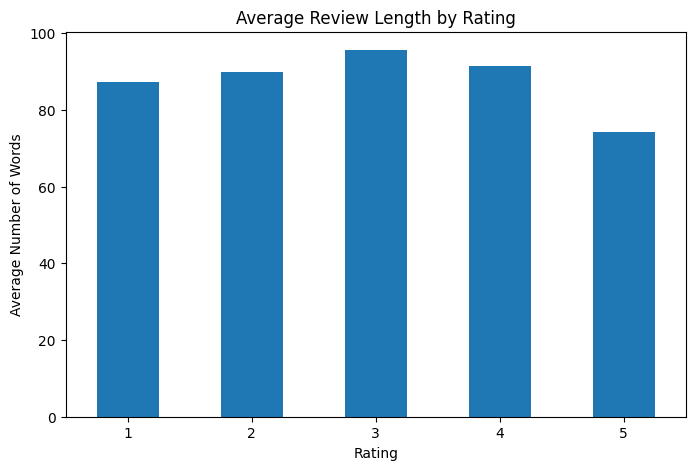

In [28]:
plt.figure(figsize=(8, 5))

avg_words_by_score.plot(kind="bar")

plt.title("Average Review Length by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Number of Words")

plt.xticks(rotation=0)

plt.show()